# 02 · Vingt ans de prix à la pompe

Le notebook 01 décrivait une photo, celle du 19 octobre 2026. Celui-ci remonte le temps : chaque changement de prix de chaque station depuis janvier 2007, soit plus de 60 millions de lignes.

**Questions**
1. Comment les prix ont-ils évolué depuis 2007, et où se situe 2026 ?
2. Le gazole est-il toujours moins cher que l'essence ?
3. Les écarts entre stations se creusent-ils ?
4. D'où viennent les prix ronds identiques observés en 2026 ?
5. Les écarts entre régions sont-ils stables ?
6. Y a-t-il un bon jour pour faire le plein ?

Les fichiers annuels sont publiés dans la release `historique` du dépôt : `gh release download historique --dir data/historique`. Chaque fichier a une fiche `prix_AAAA.json` qui indique le commit qui l'a produit.

In [1]:
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import polars as pl

from carburants import analyse

HISTORIQUE = Path("../data/historique")
FIGURES = Path("../rapports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
PRINCIPAUX = ["Gazole", "SP95", "E10", "SP98"]

pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(140)

BLEU, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#8a5cd6"
TEXTE, TEXTE_2, GRILLE, FOND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
COULEURS = {"Gazole": BLEU, "SP95": ORANGE, "E10": AQUA, "SP98": VIOLET}
plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND, "savefig.facecolor": FOND,
    "axes.edgecolor": GRILLE, "axes.labelcolor": TEXTE_2, "axes.titlecolor": TEXTE,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "xtick.color": TEXTE_2, "ytick.color": TEXTE_2, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

def sauver(fig, nom):
    fig.savefig(FIGURES / f"{nom}.png")

def euros(x, decimales=2):
    return f"{x:.{decimales}f} €".replace(".", ",")

## Chargement et série hebdomadaire

L'historique liste les changements de prix, pas les prix en vigueur : une station qui garde le même prix trois semaines n'apparaît qu'une fois. On reconstruit donc une série **hebdomadaire** par station et par carburant : le dernier prix publié dans la semaine, prolongé au plus trois semaines s'il ne change pas (au-delà, la station a probablement cessé de déclarer). La semaine lisse aussi un défaut des fichiers 2015-2016, dont les minutes ne sont pas fiables.

In [2]:
prix = analyse.charger_historique(HISTORIQUE)
resume = prix.group_by(annee=pl.col("maj").dt.year()).agg(lignes=pl.len(), stations=pl.col("station_id").n_unique()).sort("annee").collect()
print(f"{resume['lignes'].sum():,} prix publiés de {resume['annee'].min()} à {resume['annee'].max()}")
resume

64,065,362 prix publiés de 2007 à 2026


annee,lignes,stations
i32,u32,u32
2007,865796,7356
2008,1419376,7789
2009,1396403,8155
2010,1442915,8405
2011,1611215,8653
2012,1902921,9018
2013,2146743,9386
2014,2197941,9731
2015,3300813,9718


In [3]:
hebdo = analyse.prix_hebdo(prix.filter(pl.col("carburant").is_in(PRINCIPAUX)))
stats = analyse.statistiques_hebdo(hebdo)
# Les premières semaines de 2007 et les débuts de l'E10 (2009) et du SP98 (2013) ne couvrent que peu de stations
stats = stats.filter(pl.col("stations") >= 500)
print(f"{hebdo.height:,} prix hebdomadaires")

23,914,682 prix hebdomadaires


## 1. Vingt ans de prix

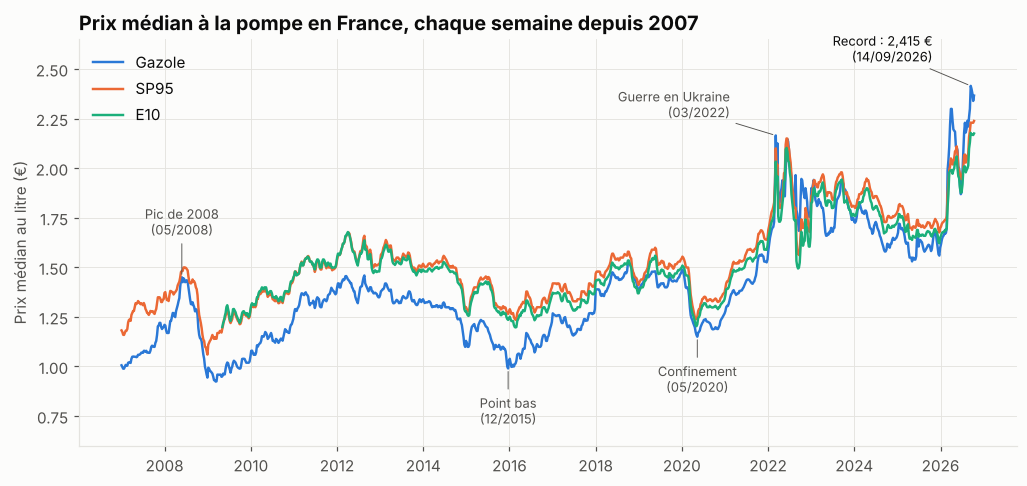

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.8))
for carburant in ["Gazole", "SP95", "E10"]:
    serie = stats.filter(carburant=carburant)
    ax.plot(serie["semaine"], serie["mediane"], color=COULEURS[carburant], linewidth=1.6, label=carburant)
# Extrêmes du gazole sur quelques périodes connues
evenements = [
    ((2008, 2008), "max", "Pic de 2008"),
    ((2015, 2016), "min", "Point bas"),
    ((2020, 2020), "min", "Confinement"),
    ((2022, 2022), "max", "Guerre en Ukraine"),
]
for (debut, fin), sens, libelle in evenements:
    periode = stats.filter(pl.col("carburant") == "Gazole", pl.col("semaine").dt.year().is_between(debut, fin)).sort("mediane")
    semaine, valeur = periode.row(-1 if sens == "max" else 0, named=True)["semaine"], periode.row(-1 if sens == "max" else 0, named=True)["mediane"]
    decalage = (-30, 12) if libelle == "Guerre en Ukraine" else (0, 28 if sens == "max" else -36)
    ax.annotate(f"{libelle}\n({semaine:%m/%Y})", (semaine, valeur), xytext=decalage, textcoords="offset points",
                ha="right" if libelle == "Guerre en Ukraine" else "center", fontsize=8.5, color=TEXTE_2, arrowprops={"arrowstyle": "-", "color": TEXTE_2, "lw": 0.6})
record = stats.filter(carburant="Gazole").sort("mediane").row(-1, named=True)
ax.annotate(f"Record : {euros(record['mediane'], 3)}\n({record['semaine']:%d/%m/%Y})", (record["semaine"], record["mediane"]),
            xytext=(-25, 14), textcoords="offset points", ha="right", va="bottom", fontsize=8.5, color=TEXTE,
            arrowprops={"arrowstyle": "-", "color": TEXTE_2, "lw": 0.6})
ax.set_ylim(0.6, 2.65)
ax.set_ylabel("Prix médian au litre (€)")
ax.set_title("Prix médian à la pompe en France, chaque semaine depuis 2007")
ax.legend(frameon=False, labelcolor=TEXTE, loc="upper left")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
sauver(fig, "06_vingt_ans_de_prix")

In [5]:
annuel = (
    stats.with_columns(annee=pl.col("semaine").dt.year())
    .group_by("annee", "carburant").agg(pl.col("mediane").mean().round(3))
    .pivot(on="carburant", index="annee", values="mediane").sort("annee")
    .select("annee", *PRINCIPAUX)
)
annuel

annee,Gazole,SP95,E10,SP98
i32,f64,f64,f64,f64
2007,1.082,1.279,null,null
2008,1.257,1.357,null,null
2009,0.99,1.215,1.259,null
2010,1.141,1.354,1.366,null
2011,1.338,1.508,1.513,null
2012,1.397,1.579,1.567,null
2013,1.351,1.549,1.53,1.567
2014,1.279,1.489,1.463,1.53
2015,1.143,1.361,1.335,1.401


In [6]:
# 2026 en détail : la hausse de mars
recent = stats.filter(pl.col("carburant") == "Gazole", pl.col("semaine") >= pl.date(2026, 1, 1)).select("semaine", "mediane", "p10", "p90")
avant = recent.filter(semaine=date(2026, 2, 23))["mediane"].item()
apres = recent.filter(semaine=date(2026, 3, 30))["mediane"].item()
print(f"Gazole : {euros(avant, 3)} la semaine du 23 février, {euros(apres, 3)} celle du 30 mars 2026, soit +{(apres - avant) * 100:.0f} centimes en cinq semaines")
recent[::4]

Gazole : 1,699 € la semaine du 23 février, 2,299 € celle du 30 mars 2026, soit +60 centimes en cinq semaines


semaine,mediane,p10,p90
date,f64,f64,f64
2026-01-05,1.616,1.579,1.719
2026-02-02,1.669,1.629,1.774
2026-03-02,1.99,1.929,2.035
2026-03-30,2.299,2.09,2.413
2026-04-27,2.189,2.09,2.289
2026-05-25,2.09,1.989,2.189
2026-06-22,1.869,1.813,1.995
2026-07-20,2.179,2.128,2.25
2026-08-17,2.239,2.189,2.303


Le gazole est passé d'environ 1,08 € en moyenne en 2007 à 1,86 € en 2022, puis 2,07 € sur les neuf premiers mois et demi de 2026. Les grandes secousses se lisent directement : le pic de 2008, la chute de fin 2008, le point bas de fin 2015, le creux du confinement de 2020, puis la flambée de mars 2022.

**2026 bat tous les records.** Le gazole est passé de 1,70 € la semaine du 23 février à 2,30 € la semaine du 30 mars, soit 60 centimes en cinq semaines, puis a atteint 2,415 € à la mi-septembre, au-dessus du pic de 2022 (2,165 €). Ces données ne disent pas pourquoi : le notebook 03 confrontera ces prix au cours du Brent et au taux de change.

## 2. Le gazole a perdu son avantage

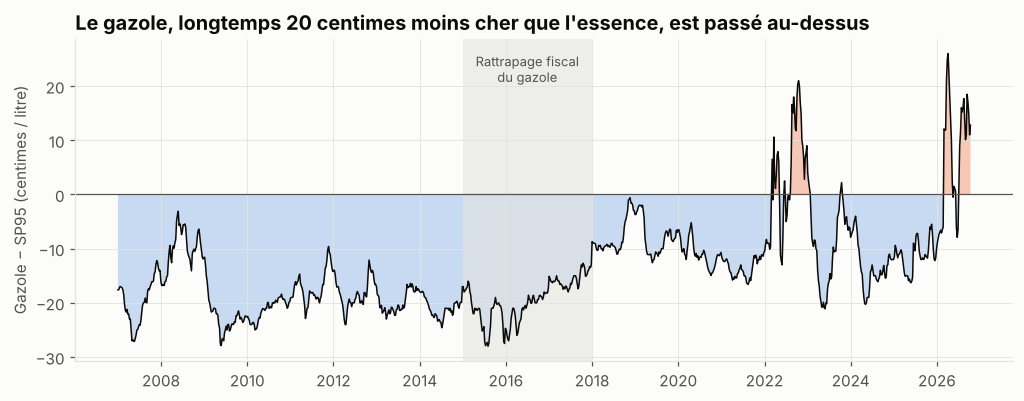

In [7]:
ecart = (
    stats.filter(pl.col("carburant").is_in(["Gazole", "SP95"]))
    .pivot(on="carburant", index="semaine", values="mediane")
    .drop_nulls()
    .with_columns(ecart=(pl.col("Gazole") - pl.col("SP95")) * 100)
    .sort("semaine")
)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(ecart["semaine"], ecart["ecart"], 0, where=ecart["ecart"] < 0, color=BLEU, alpha=0.25, linewidth=0)
ax.fill_between(ecart["semaine"], ecart["ecart"], 0, where=ecart["ecart"] >= 0, color=ORANGE, alpha=0.35, linewidth=0)
ax.plot(ecart["semaine"], ecart["ecart"], color=TEXTE, linewidth=1)
ax.axhline(0, color=TEXTE_2, linewidth=0.8)
ax.axvspan(date(2015, 1, 1), date(2018, 1, 1), color=GRILLE, alpha=0.6, linewidth=0)
ax.text(date(2016, 7, 1), ecart["ecart"].max(), "Rattrapage fiscal\ndu gazole", ha="center", va="top", fontsize=8.5, color=TEXTE_2)
ax.set_ylabel("Gazole − SP95 (centimes / litre)")
ax.set_title("Le gazole, longtemps 20 centimes moins cher que l'essence, est passé au-dessus")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
sauver(fig, "07_ecart_gazole_essence")

In [8]:
ecart.group_by(annee=pl.col("semaine").dt.year()).agg(ecart_centimes=pl.col("ecart").mean().round(1)).sort("annee")

annee,ecart_centimes
i32,f64
2007,-19.7
2008,-10.1
2009,-22.5
2010,-21.3
2011,-17.1
2012,-18.2
2013,-19.8
2014,-21.0
2015,-21.8


Jusqu'en 2014, le gazole coûtait environ 20 centimes de moins que le SP95, grâce à un avantage fiscal ancien. Entre 2015 et 2018, la taxe sur le gazole a été relevée plus vite que celle sur l'essence (le « rattrapage »), et l'écart est tombé à 8 centimes en 2018-2019, avant que la trajectoire ne soit gelée fin 2018.

Lors des deux grandes crises, le gazole est passé **au-dessus** de l'essence : 3 centimes de plus en moyenne en 2022, 7 centimes en 2026, avec un pic à 26 centimes au printemps 2026. Le gazole est le carburant le plus exposé aux tensions d'approvisionnement : l'Europe en importe une grande partie, et en 2022 une bonne part venait de Russie.

## 3. Dispersion et prix ronds

In [9]:
# Part des stations au prix le plus fréquent de la semaine (le « prix modal »)
def prix_modal(carburant):
    return (
        hebdo.filter(carburant=carburant)
        .group_by("semaine", "prix").agg(n=pl.len())
        .sort("n")
        .group_by("semaine").agg(modal=pl.col("prix").last(), n_modal=pl.col("n").last(), n=pl.col("n").sum())
        .with_columns(part=pl.col("n_modal") / pl.col("n"), carburant=pl.lit(carburant))
        .sort("semaine")
    )

modal = pl.concat([prix_modal("Gazole"), prix_modal("E10")])
modal.with_columns(annee=pl.col("semaine").dt.year()).group_by("annee", "carburant").agg(
    part_moyenne=(pl.col("part").mean() * 100).round(1), part_max=(pl.col("part").max() * 100).round(1)
).sort("annee", "carburant").pivot(on="carburant", index="annee", values=["part_moyenne", "part_max"])

annee,part_moyenne_Gazole,part_moyenne_E10,part_max_Gazole,part_max_E10
i32,f64,f64,f64,f64
2007,7.5,null,11.1,null
2008,6.1,null,11.3,null
2009,8.3,5.1,12.5,11.3
2010,7.6,4.3,9.9,6.0
2011,6.3,3.6,8.4,5.6
2012,6.4,3.8,9.1,5.5
2013,6.5,4.3,9.1,5.5
2014,6.4,4.7,8.2,6.8
2015,7.0,5.1,10.6,8.6


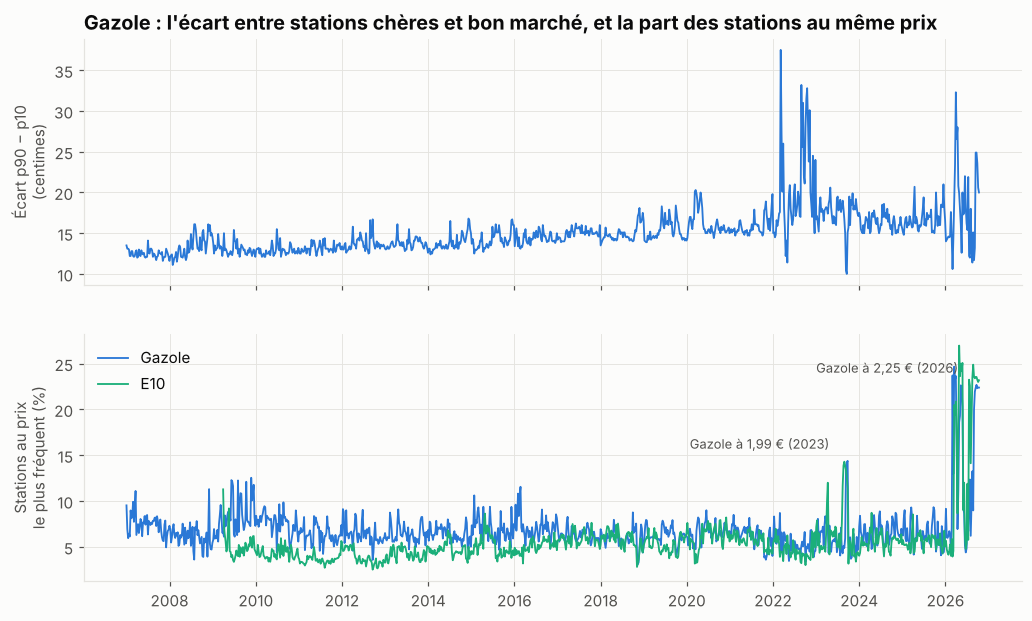

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
gazole = stats.filter(carburant="Gazole")
axes[0].plot(gazole["semaine"], (gazole["p90"] - gazole["p10"]) * 100, color=BLEU, linewidth=1.2)
axes[0].set_ylabel("Écart p90 − p10\n(centimes)")
axes[0].set_title("Gazole : l'écart entre stations chères et bon marché, et la part des stations au même prix")
for carburant, couleur in [("Gazole", BLEU), ("E10", AQUA)]:
    serie = modal.filter(carburant=carburant)
    axes[1].plot(serie["semaine"], serie["part"] * 100, color=couleur, linewidth=1.2, label=carburant)
axes[1].set_ylabel("Stations au prix\nle plus fréquent (%)")
axes[1].legend(frameon=False, labelcolor=TEXTE, loc="upper left")
for libelle, semaine in [("1,99 € (2023)", date(2023, 9, 25)), ("2,25 € (2026)", date(2026, 9, 21))]:
    part = modal.filter(carburant="Gazole", semaine=semaine)["part"].item() * 100
    axes[1].annotate(f"Gazole à {libelle}", (semaine, part), xytext=(-12, 8), textcoords="offset points", ha="right", fontsize=8.5, color=TEXTE_2)
axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
sauver(fig, "08_dispersion_prix_ronds")

In [11]:
# Qui pratique ces prix ronds ? L'enseigne (OpenStreetMap) des stations au gazole à 2,25 € le 19 octobre 2026
enseignes = pl.read_parquet(sorted(Path("../data/enseignes").glob("stations_enseignes_*.parquet"))[-1])
photo = hebdo.filter(carburant="Gazole", semaine=hebdo["semaine"].max())
(
    photo.join(enseignes.select("station_id", "enseigne"), on="station_id", how="left")
    .group_by(enseigne=pl.col("enseigne").fill_null("(inconnue)"))
    .agg(stations=pl.len(), a_2_25=(pl.col("prix") == 2.25).sum())
    .with_columns(part_a_2_25=(pl.col("a_2_25") / pl.col("stations") * 100).round(1))
    .sort("stations", descending=True)
    .head(10)
)

enseigne,stations,a_2_25,part_a_2_25
str,u32,u32,f64
"""TotalEnergies""",1887,1763,93.4
"""(inconnue)""",1767,271,15.3
"""Intermarché""",1325,3,0.2
"""Carrefour""",1102,11,1.0
"""Système U""",649,2,0.3
"""E.Leclerc""",633,3,0.5
"""Esso""",551,11,2.0
"""Avia""",458,10,2.2
"""Auchan""",228,0,0.0


En temps normal, le prix le plus fréquent de la semaine ne concerne que 6 à 7 % des stations. Deux épisodes sortent du lot :
- **2023** : jusqu'à 14 % des stations au même prix, 1,99 €, pour le gazole comme pour l'E10. TotalEnergies avait alors annoncé plafonner ses prix à 1,99 € le litre dans ses stations.
- **2026** : jusqu'à 25 % des stations pour le gazole (à 2,09 € au printemps, puis 2,25 € depuis août) et 27 % pour l'E10 (à 1,99 €). L'appariement avec OpenStreetMap ne laisse pas de doute : la dernière semaine, 93 % des stations TotalEnergies affichent le gazole à 2,25 €, contre au plus 2 % des autres enseignes identifiées.

Ce plafonnement « écrase » la distribution : le 10e centile du gazole est collé à 2,25 €, ce qui rend la médiane et la dispersion moins informatives en 2026. Le modèle de prix devra traiter l'enseigne TotalEnergies à part.

L'écart entre les 10 % de stations les plus chères et les 10 % les moins chères est passé d'environ 13 centimes (2007-2012) à 16-18 centimes dans les années 2020, avec des pointes au-delà de 30 centimes au début des crises, quand toutes les stations ne répercutent pas la hausse au même rythme.

## 4. Géographie : des écarts qui durent

In [12]:
stations = analyse.stations_connues(HISTORIQUE)
par_dep = analyse.statistiques_hebdo(
    hebdo.filter(carburant="Gazole").join(stations.select(station_id="id", departement="departement"), on="station_id"),
    par=["departement"],
)
national = stats.filter(carburant="Gazole").select("semaine", national="mediane")
ecarts_dep = (
    par_dep.filter(pl.col("stations") >= 15, ~pl.col("departement").str.starts_with("97"))
    .join(national, on="semaine")
    .with_columns(ecart=(pl.col("mediane") - pl.col("national")) * 100, annee=pl.col("semaine").dt.year())
    .group_by("departement", "annee").agg(pl.col("ecart").mean())
)
matrice = ecarts_dep.pivot(on="annee", index="departement", values="ecart", sort_columns=True)
annees = [c for c in matrice.columns if c != "departement"]
matrice = matrice.with_columns(moyenne=pl.mean_horizontal(annees)).sort("moyenne").drop_nulls()
# Stabilité : corrélation des rangs entre deux années éloignées
print("Corrélation de rang des écarts départementaux 2010 / 2025 :",
      round(matrice.select(pl.corr(pl.col("2010").rank(), pl.col("2025").rank())).item(), 2))
pl.concat([matrice.head(5), matrice.tail(5)]).select("departement", "2010", "2015", "2020", "2025", "moyenne").with_columns(pl.exclude("departement").round(1))

Corrélation de rang des écarts départementaux 2010 / 2025 : 0.76


departement,2010,2015,2020,2025,moyenne
str,f64,f64,f64,f64,f64
"""17""",-3.3,-4.7,-2.9,-3.7,-3.6
"""79""",-2.9,-4.0,-2.1,-3.4,-3.1
"""16""",-2.6,-4.1,-1.6,-2.9,-2.7
"""44""",-1.9,-1.7,-2.8,-3.6,-2.7
"""85""",-1.7,-1.7,-2.7,-3.4,-2.5
"""06""",5.0,6.9,7.9,6.5,5.7
"""93""",4.5,6.7,9.6,8.2,6.4
"""20""",8.3,10.9,14.9,13.5,9.9
"""92""",7.5,9.4,13.6,13.6,10.2


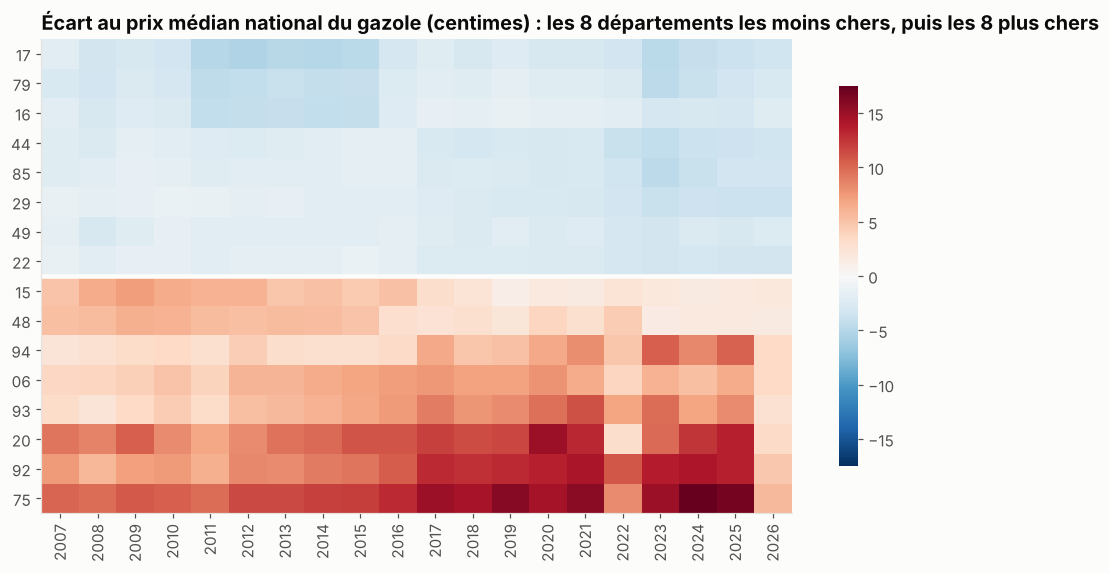

In [13]:
selection = pl.concat([matrice.head(8), matrice.tail(8)])
fig, ax = plt.subplots(figsize=(11, 5.6))
valeurs = selection.select(annees).to_numpy()
limite = np.nanmax(np.abs(valeurs))
image = ax.imshow(valeurs, cmap="RdBu_r", vmin=-limite, vmax=limite, aspect="auto")
ax.set_yticks(range(selection.height), selection["departement"])
ax.set_xticks(range(len(annees)), annees, rotation=90)
ax.axhline(7.5, color=FOND, linewidth=3)
ax.grid(False)
ax.set_title("Écart au prix médian national du gazole (centimes) : les 8 départements les moins chers, puis les 8 plus chers")
barre = fig.colorbar(image, ax=ax, shrink=0.8)
barre.outline.set_visible(False)
sauver(fig, "09_departements")

Les écarts géographiques sont **remarquablement stables** : le classement des départements de 2010 et celui de 2025 sont corrélés à 0,76. Les moins chers sont toujours sur la façade atlantique (Charente-Maritime, Deux-Sèvres, Charente, Loire-Atlantique, Vendée), 2,5 à 3,5 centimes sous la médiane nationale. Les plus chers sont Paris et la petite couronne, la Corse et les Alpes-Maritimes, et l'écart de Paris se creuse : +10 centimes en 2010, +17 en 2025.

Exception notable : en 2026, les écarts se resserrent, et la Corse, d'ordinaire 8 à 15 centimes au-dessus de la moyenne, est passée en dessous pendant la flambée. Ses prix ont suivi la hausse plus lentement. C'est pourquoi la photo du 19 octobre (notebook 01) la classait parmi les moins chères : un constat vrai ce jour-là, pas une tendance de fond.

## 5. Quel jour faire le plein ?

In [14]:
# Sens de chaque changement de prix du gazole, selon le jour de la semaine (depuis 2017)
changements = (
    prix.filter(pl.col("carburant") == "Gazole", pl.col("maj") >= pl.datetime(2016, 12, 1))
    .sort("station_id", "maj")
    .with_columns(delta=pl.col("prix") - pl.col("prix").shift(1).over("station_id"))
    .filter(pl.col("maj") >= pl.datetime(2017, 1, 1), pl.col("delta") != 0)
    .group_by(jour=pl.col("maj").dt.weekday())
    .agg(changements=pl.len(), hausses=(pl.col("delta") > 0).sum())
    .with_columns(part_hausses=(pl.col("hausses") / pl.col("changements") * 100).round(1))
    .sort("jour")
    .collect()
)
JOURS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
changements.with_columns(jour=pl.col("jour").replace_strict(range(1, 8), JOURS))

jour,changements,hausses,part_hausses
str,u32,u32,f64
"""lundi""",1147613,672493,58.6
"""mardi""",1534645,866367,56.5
"""mercredi""",1427210,764104,53.5
"""jeudi""",1406233,730903,52.0
"""vendredi""",1763431,800090,45.4
"""samedi""",1080530,541640,50.1
"""dimanche""",147060,91278,62.1


In [15]:
# Niveau des prix selon le jour : prix en vigueur chaque jour de 2025 (dernier prix publié, prolongé), comparé à la moyenne de sa semaine
annee = prix.filter(pl.col("carburant") == "Gazole", pl.col("maj").dt.year().is_in([2024, 2025]))
jours = (
    annee.with_columns(jour=pl.col("maj").dt.date()).sort("maj")
    .group_by("station_id", "jour").agg(pl.col("prix").last())
    .collect()
    .sort("station_id", "jour")
    .upsample("jour", every="1d", group_by="station_id")
    .with_columns(pl.col("prix").forward_fill(limit=6).over("station_id"), pl.col("station_id").forward_fill())
    .filter(pl.col("jour").dt.year() == 2025)
    .drop_nulls("prix")
)
quotidien = jours.group_by("jour").agg(moyenne=pl.col("prix").mean()).sort("jour").with_columns(semaine=pl.col("jour").dt.truncate("1w"))
quotidien = quotidien.with_columns(ecart=(pl.col("moyenne") - pl.col("moyenne").mean().over("semaine")) * 1000)
effet_jour = quotidien.filter(pl.col("semaine").count().over("semaine") == 7).group_by(j=pl.col("jour").dt.weekday()).agg(
    ecart_millimes=pl.col("ecart").mean().round(2)).sort("j")
effet_jour.with_columns(jour=pl.col("j").replace_strict(range(1, 8), JOURS)).drop("j")

ecart_millimes,jour
f64,str
1.53,"""lundi"""
1.49,"""mardi"""
1.22,"""mercredi"""
0.92,"""jeudi"""
-2.68,"""vendredi"""
-1.63,"""samedi"""
-0.85,"""dimanche"""


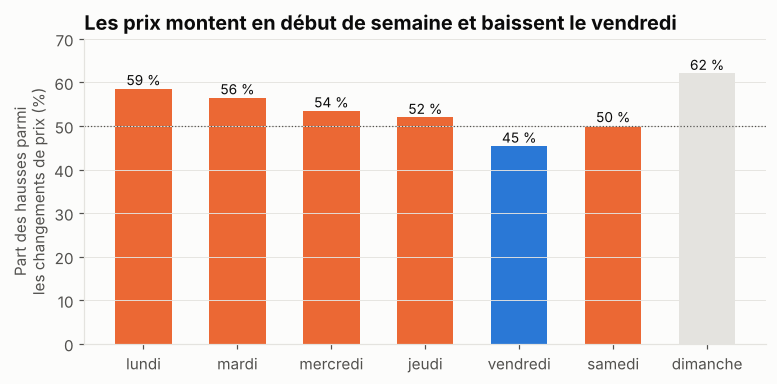

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.6))
# Le dimanche compte peu de changements (moins de 2 %) : grisé
couleurs = [GRILLE if j == 7 else ORANGE if v > 50 else BLEU for j, v in zip(changements["jour"], changements["part_hausses"])]
ax.bar(JOURS, changements["part_hausses"], color=couleurs, width=0.6)
ax.axhline(50, color=TEXTE_2, linewidth=0.8, linestyle=":")
for i, v in enumerate(changements["part_hausses"]):
    ax.text(i, v + 0.8, f"{v:.0f} %", ha="center", fontsize=9, color=TEXTE)
ax.set_ylim(0, 70)
ax.set_ylabel("Part des hausses parmi\nles changements de prix (%)")
ax.set_title("Les prix montent en début de semaine et baissent le vendredi")
ax.grid(axis="x", visible=False)
sauver(fig, "10_jour_de_la_semaine")

Depuis 2017, 59 % des changements de prix du lundi sont des hausses, contre 45 % le vendredi, seul jour où les baisses dominent. Le niveau de prix suit le même cycle : en 2025, le gazole était en moyenne 0,15 centime au-dessus de la moyenne de sa semaine le lundi, et 0,27 centime en dessous le vendredi.

L'effet est réel mais **minuscule** : environ 0,4 centime par litre entre lundi et vendredi, soit 20 centimes sur un plein de 50 litres. Choisir sa station (13 à 28 centimes d'écart entre le premier et le dernier décile, notebook 01) compte 30 à 70 fois plus que choisir son jour.

## 6. Des prix qui bougent de plus en plus souvent

In [17]:
frequence = (
    prix.filter(carburant="Gazole")
    .sort("station_id", "maj")
    .with_columns(delta=pl.col("prix") - pl.col("prix").shift(1).over("station_id"))
    .group_by(annee=pl.col("maj").dt.year())
    .agg(changements=(pl.col("delta") != 0).sum(), stations=pl.col("station_id").n_unique())
    .with_columns(par_station_et_semaine=(pl.col("changements") / pl.col("stations") / 52).round(2))
    .sort("annee")
    .collect()
)
frequence.select("annee", "par_station_et_semaine")

annee,par_station_et_semaine
i32,f64
2007,0.87
2008,1.45
2009,1.2
2010,1.15
2011,1.25
2012,1.36
2013,1.27
2014,1.13
2015,1.37


Une station change le prix de son gazole un peu plus d'une fois par semaine en moyenne entre 2008 et 2020, et plus souvent depuis : 2,4 fois par semaine en 2022, environ 2 en 2025. Les prix bougent davantage quand le pétrole est volatil, ce qui rend la collecte quotidienne d'autant plus utile.

## À retenir

- **2026 est une année record** : le gazole a dépassé 2,40 € à la mi-septembre, au-dessus du pic de 2022, après une hausse de 60 centimes en cinq semaines au printemps.
- **Le gazole a perdu son avantage** : 20 centimes moins cher que l'essence jusqu'en 2014, il est passé au-dessus lors des crises de 2022 et 2026.
- **Les prix ronds de 2026 viennent de TotalEnergies** : 93 % de ses stations sont au même prix (2,25 € pour le gazole), ce qui déforme les statistiques nationales. L'enseigne sera une variable clé du modèle (étape 5).
- **La géographie est stable** : façade atlantique bon marché, Paris, Corse et Côte d'Azur chères, avec un écart parisien qui s'accentue. La photo d'un seul jour peut tromper (la Corse en 2026).
- **Le jour du plein ne compte presque pas** (0,4 centime entre lundi et vendredi) ; la station, beaucoup.
- Prochaine étape : expliquer ces variations par le cours du Brent et l'euro, et mesurer si les prix montent plus vite qu'ils ne baissent (« fusée et plume »).